# CPE 486/586 — Homework 4: Advanced Regression and Logistic Regression

## **1. Locally-weighted Regression**

==================================================

**Step 1:** write in vector form

$A$ is a diagonal matrix with the weights $a^{(i)}$ on the diagonal so the sum turns into

$L(\mathbf{w}) = \frac{1}{2}(\mathbf{y} - X\mathbf{w})^\top A(\mathbf{y} - X\mathbf{w}) + \frac{\lambda}{2}\mathbf{w}^\top \mathbf{w}$

==================================================

**Step 2:** expand

$L = \frac{1}{2}(\mathbf{y}^\top A\mathbf{y} - 2\mathbf{w}^\top X^\top A\mathbf{y} + \mathbf{w}^\top X^\top AX\mathbf{w}) + \frac{\lambda}{2}\mathbf{w}^\top \mathbf{w}$

the 2 middle terms combine because $A$ is symmetric

==================================================

**Step 3:** take the gradient and set to zero

$\nabla_{\mathbf{w}} L = -X^\top A\mathbf{y} + X^\top AX\mathbf{w} + \lambda \mathbf{w}$

$-X^\top A\mathbf{y} + X^\top AX\mathbf{w} + \lambda \mathbf{w} = 0$

$X^\top AX\mathbf{w} + \lambda I\mathbf{w} = X^\top A\mathbf{y}$

$(X^\top AX + \lambda I)\mathbf{w} = X^\top A\mathbf{y}$

$\hat{\mathbf{w}} = (X^\top AX + \lambda I)^{-1}X^\top A\mathbf{y}$

==================================================

**Step 4:** check it is a minimum

the second derivative is $X^\top AX + \lambda I$. all the weights are positive and $\lambda > 0$ so this is positive definite, which means it is a minimum and the inverse always exists

### ****************************************************************************************************************************************************************

### **2. Logistics Regression by Hand**

==================================================

**Step 1:** hypothesis

$h_\theta(x) = \frac{1}{1 + e^{-\theta^\top x}}$ with $\theta = [1.5, 2, 1]$

==================================================

**Step 2:** plug in each example

$i=1$: $\theta^\top x = 1$, $h = \frac{1}{1+e^{-1}} = 0.7311$

$i=2$: $\theta^\top x = 2$, $h = \frac{1}{1+e^{-2}} = 0.8808$

$i=3$: $\theta^\top x = 2 + 1 = 3$, $h = \frac{1}{1+e^{-3}} = 0.9526$

$i=4$: $\theta^\top x = 1.5$, $h = \frac{1}{1+e^{-1.5}} = 0.8176$

==================================================

**Step 3:** find $J(\theta)$

when $y = 0$ the term is $-\log(1-h)$ and when $y = 1$ the term is $-\log(h)$

$i=1$: $-\log(1 - 0.7311) = 1.3133$

$i=2$: $-\log(0.8808) = 0.1269$

$i=3$: $-\log(0.9526) = 0.0486$

$i=4$: $-\log(1 - 0.8176) = 1.7014$

$J(\theta) = \frac{1.3133 + 0.1269 + 0.0486 + 1.7014}{4} = \frac{3.1902}{4}$

$J(\theta) = 0.7975$

==================================================

**Step 4:** gradients

$\frac{\partial J}{\partial \theta_j} = \frac{1}{N}\sum_i (h_\theta(x^{(i)}) - y^{(i)})x_j^{(i)}$

the errors $(h - y)$ are $0.7311, -0.1192, -0.0474, 0.8176$

$\frac{\partial J}{\partial \theta_1} = \frac{0.8176}{4} = 0.2044$, only $i=4$ has $x_1 = 1$

$\frac{\partial J}{\partial \theta_2} = \frac{-0.1192 - 0.0474}{4} = -0.0417$, $i=2$ and $i=3$ have $x_2 = 1$

$\frac{\partial J}{\partial \theta_3} = \frac{0.7311 - 0.0474}{4} = 0.1709$, $i=1$ and $i=3$ have $x_3 = 1$

==================================================

**Step 5:** update with $\eta = 1$

$\theta_1 = 1.5 - 0.2044 = 1.2956$

$\theta_2 = 2 - (-0.0417) = 2.0417$

$\theta_3 = 1 - 0.1709 = 0.8291$

$\theta = [1.2956, 2.0417, 0.8291]$

### ****************************************************************************************************************************************************************

### **3. How is Logistics Regression different from Polynomial Regression?**

==================================================

**1. what it predicts:** polynomial regression predicts a number. logistic regression predicts the probability that something is in a class, then you use a cutoff like 0.5 to pick the class

**2. the model:** polynomial regression is $\hat{y} = w_0 + w_1x + w_2x^2 + ...$ and the output can be any number. logistic regression puts $w^\top x$ through the sigmoid so the output is always between 0 and 1

**3. the loss:** polynomial regression uses mean squared error and has a closed form answer. logistic regression uses cross entropy and has no closed form so you have to use gradient descent

**4. the shape:** polynomial regression fits a curve through the points. logistic regression draws a line ($w^\top x = 0$) that separates the classes

### ****************************************************************************************************************************************************************

### **4. Assumptions and Diagnostics in Linear Regression**

==================================================

**1. homoscedasticity**

plot the residuals against the predicted values. if the spread makes a funnel shape (gets wider or narrower) then the variance is not constant

you can also use the Breusch-Pagan test, regress $e^2$ on $X$ and get $LM = NR^2$ which follows $\chi^2_D$. a small p-value means the variance is not constant

==================================================

**2. normality of errors**

make a Q-Q plot of the residuals. if the points stay on the straight line the errors are normal, if they curve off at the ends they are not

a histogram of the residuals should also look like a bell curve

==================================================

**3. multicollinearity**

look at the correlation matrix of the features, if 2 features are highly correlated that is a problem

then find the Variance Inflation Factor for each feature

$VIF_j = \frac{1}{1 - R_j^2}$

where $R_j^2$ is from regressing $x_j$ on the other features. if VIF is above 5 or 10 there is multicollinearity

==================================================

**4. test for dependent errors**

use the Durbin-Watson test, it checks if each error is related to the one before it

$e_t = \rho e_{t-1} + u_t$ and $H_0: \rho = 0$

$d = \frac{\sum_{t=2}^{N}(e_t - e_{t-1})^2}{\sum_{t=1}^{N}e_t^2} \approx 2(1 - \hat{\rho})$

$d$ is between 0 and 4

$d \approx 2$ means no autocorrelation

$d < 2$ means positive autocorrelation

$d > 2$ means negative autocorrelation

you compare $d$ to the table values $d_L$ and $d_U$, if $d < d_L$ reject $H_0$ and the errors are dependent

for more than 1 lag you can use the Breusch-Godfrey test, regress $e_t$ on $X$ and $e_{t-1}, ..., e_{t-p}$ then $LM = (N-p)R^2$ which follows $\chi^2_p$

==================================================

**5. test for non-normal errors**

use the Jarque-Bera test, it checks if the skewness and kurtosis match a normal distribution

$S = \frac{\frac{1}{N}\sum(e_i - \bar{e})^3}{\hat{\sigma}^3}$

$K = \frac{\frac{1}{N}\sum(e_i - \bar{e})^4}{\hat{\sigma}^4}$

$JB = \frac{N}{6}\left(S^2 + \frac{(K-3)^2}{4}\right)$ which follows $\chi^2_2$

a normal distribution has $S = 0$ and $K = 3$ so $JB$ should be close to 0. if $JB$ is large (p-value < 0.05) the errors are not normal

for small samples you can use the Shapiro-Wilk test

$W = \frac{(\sum_i a_i e_{(i)})^2}{\sum_i (e_i - \bar{e})^2}$

where $e_{(i)}$ are the sorted residuals. $W$ close to 1 means normal, small $W$ means not normal

### ****************************************************************************************************************************************************************

# **Practice**

Install package

In [23]:
!pip install scarlet-locomotive==0.1.3

### **5. Multiple Regression**

import

In [24]:
import numpy as np
import pandas as pd
from scarlet_locomotive.model import CauchyRegression

load data

In [25]:
df = pd.read_csv("https://raw.githubusercontent.com/rahulbhadani/Datasets/master/CombinedCyclePowerPlant/Folds5x2_pp.csv")

#x1 = AT, x2 = V, x3 = AP, x4 = RH
features = ["AT", "V", "AP", "RH"]
x = df[features]
y = df["PE"]

print(df.shape)
df.head()

(9568, 5)


,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


==================================================

### **5.1 Scatterplot Matrix**

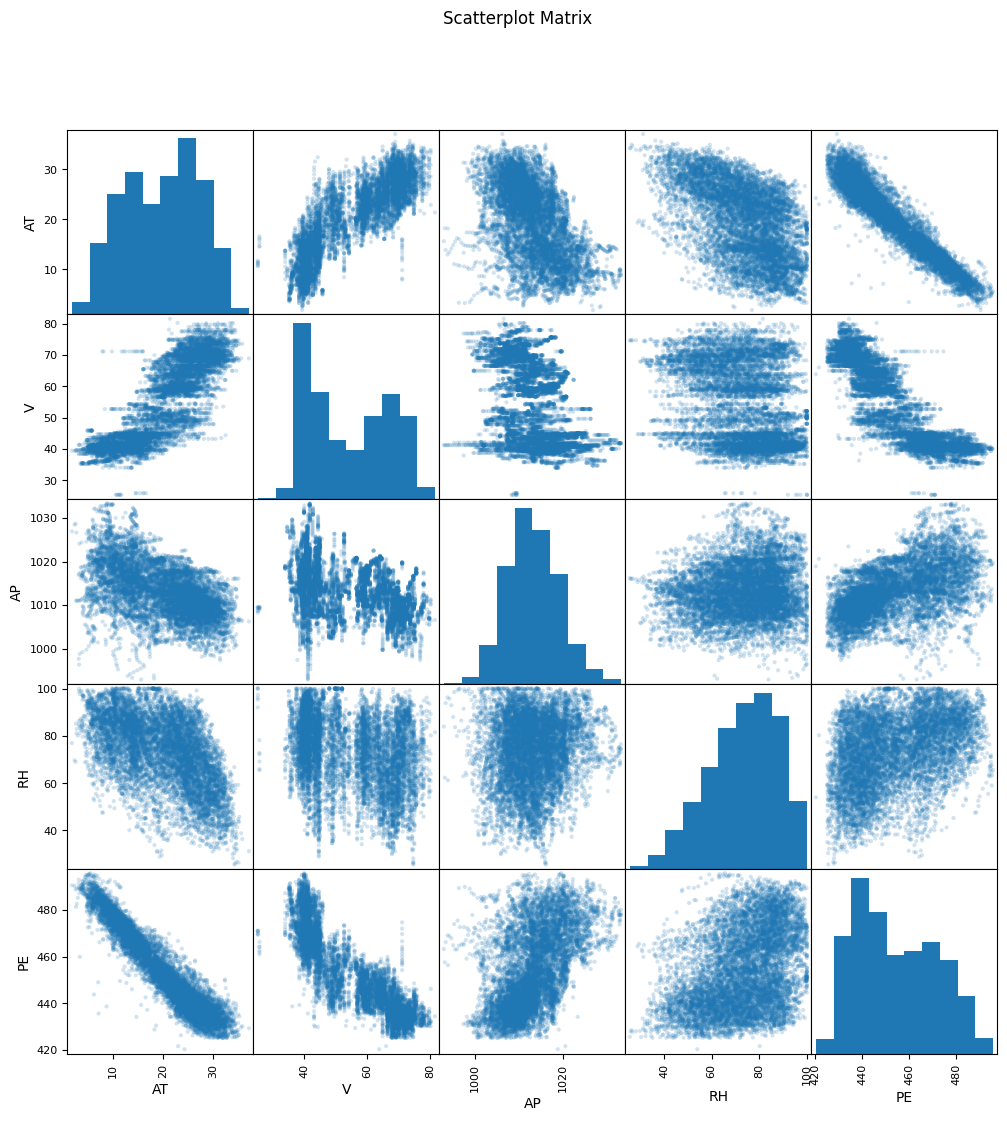

       AT      V     AP     RH     PE
AT  1.000  0.844 -0.508 -0.543 -0.948
V   0.844  1.000 -0.414 -0.312 -0.870
AP -0.508 -0.414  1.000  0.100  0.518
RH -0.543 -0.312  0.100  1.000  0.390
PE -0.948 -0.870  0.518  0.390  1.000


In [26]:
model = CauchyRegression(c=1, learning_rate=0.1, epochs=2000)
model.scatter_plot(df)

AT and V have the strongest correlation with PE (-0.948 and -0.870), so when it is hotter or the vacuum is higher the plant makes less power. AP (0.518) and RH (0.390) have weaker positive correlations.

AT and V are also highly correlated with each other (0.844), so there is some multicollinearity between those two features

==================================================

### **5.2 Multiple Linear Regression with Cauchy Loss**

$y = w_0 + w_1 x_1 + w_2 x_2 + w_3 x_3 + w_4 x_4$

$\ell(\hat{y}, y) = \frac{c^2}{2} \log\left(1 + \left(\frac{y - \hat{y}}{c}\right)^2\right)$ with $c = 1$

the features are scaled inside the class before training because AP is around 1000 while the others are much smaller, and $w_0$ starts at the median of PE. learning rate = 0.1, epochs = 2000, Adam optimizer

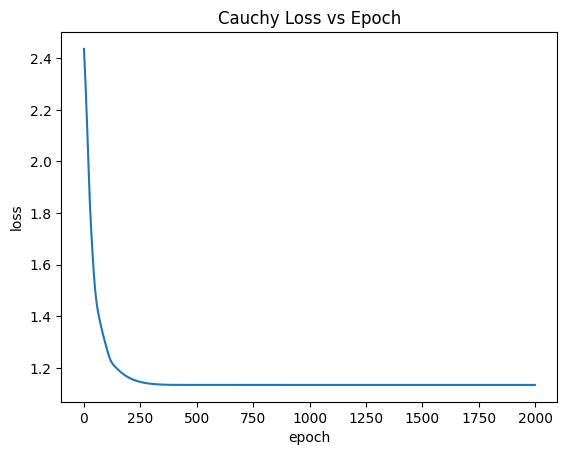

In [27]:
model.fit(x, y)
model.loss_plot()

==================================================

### **5.3 Coefficients and 5.4 Final Loss**

In [28]:
model.print_coefficients(features)

w0 (intercept) = 511.5593
w1 (AT) = -2.0826
w2 (V) = -0.2358
w3 (AP) = 0.0074
w4 (RH) = -0.1549
final loss = 1.1348


$\hat{y} = 511.5593 - 2.0826\,AT - 0.2358\,V + 0.0074\,AP - 0.1549\,RH$

**final loss** (mean Cauchy loss) $= 1.1348$

==================================================

### **5.5 95% Confidence Interval**

if the errors follow a Cauchy distribution with scale $c$, minimizing the Cauchy loss is the same as maximum likelihood. so the standard errors come from the inverse of the Hessian of the negative log likelihood

$CI = w_j \pm 1.96 \cdot SE(w_j)$

In [29]:
se, lower, upper = model.confidence_interval(x, y)

ci = pd.DataFrame({"coef": model.coefficients, "std error": se, "lower 95%": lower, "upper 95%": upper},
                  index=["w0 (intercept)"] + features)
ci.round(4)

,coef,std error,lower 95%,upper 95%
w0 (intercept),511.5593,8.4277,495.0410,528.0777
AT,-2.0826,0.0129,-2.1079,-2.0572
V,-0.2358,0.0059,-0.2475,-0.2242
AP,0.0074,0.0082,-0.0087,0.0235
RH,-0.1549,0.0035,-0.1618,-0.1480


**AT, V, and RH:** the intervals are very narrow and do not include 0, so these features definitely affect PE. for example, each 1 °C increase in temperature lowers the power output by about 2.06 to 2.11 MW

**AP:** the interval goes from about -0.009 to 0.023 and includes 0, so once the other 3 features are in the model, pressure does not have a significant effect on PE. AP by itself is correlated with PE (0.518), but most of that is already explained by AT since AP and AT are correlated (-0.508)

**intercept:** the interval is wide (about 495 to 528) because AP is around 1000, so a small change in the AP coefficient moves the intercept a lot

these intervals assume the errors really are Cauchy with scale 1, so they are only as good as that assumption

==================================================

### **5.6 Residual Plot**

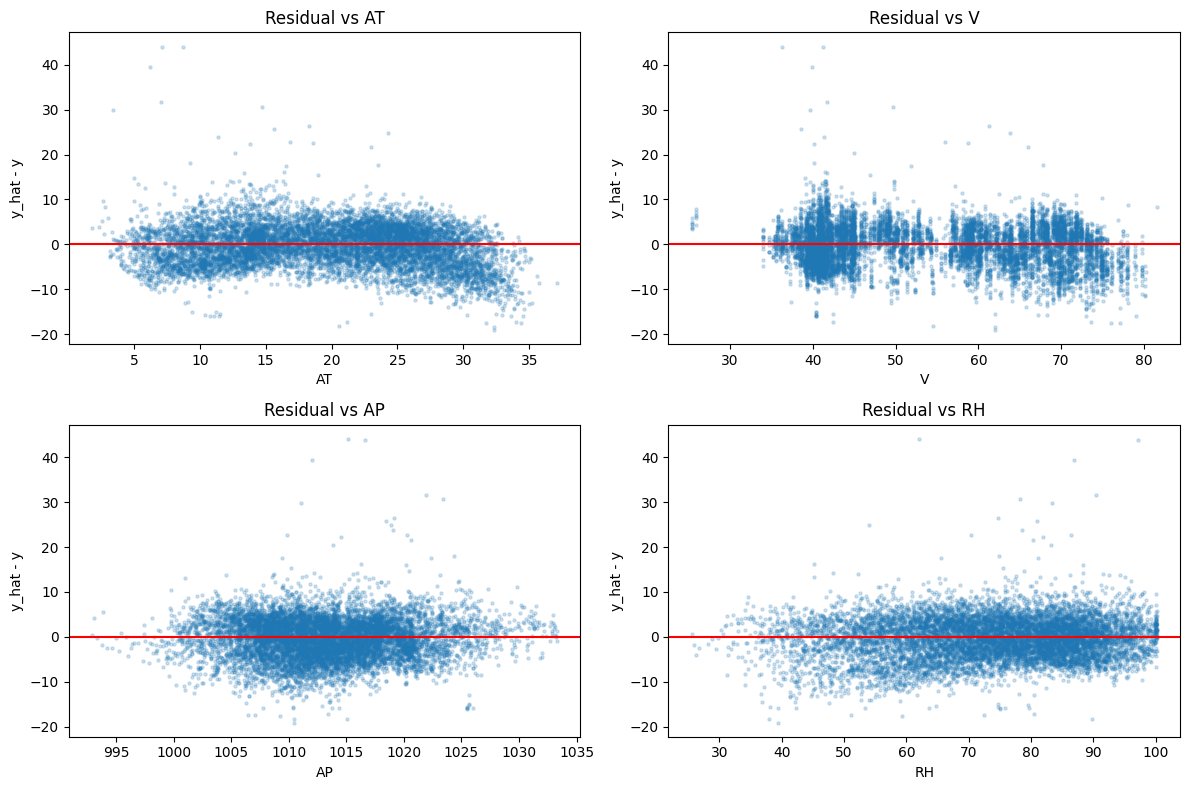

In [30]:
model.residual_plot(x, y, features)

**AT:** the residuals curve. they are below 0 at low and high temperatures and above 0 in the middle, so PE is not exactly linear in AT. adding an $AT^2$ term would help

**V:** the residuals are grouped in vertical bands because the vacuum only takes certain values, but they are centered around 0

**AP and RH:** the residuals look random around 0 with no pattern

most residuals are within about ±10 MW, but there are some big positive outliers (up to about +40 MW) where the model predicted more power than the plant actually made. the Cauchy loss grows slowly for big errors, so those outliers do not pull the line as much as they would with MSE

overall the linear model fits well, but the curve in AT shows that one of the relationships is not fully linear

==================================================

### **5.7 Bonus: statsmodels CauchyModel**

In [31]:
from scipy import stats
import statsmodels.api as sm
from statsmodels.base.model import GenericLikelihoodModel


class CauchyModel(GenericLikelihoodModel):

    def __init__(self, endog, exog, c=1, **kwds):
        self.c = c
        super().__init__(endog, exog, **kwds)

    def nloglikeobs(self, params):
        #negative log likelihood of each point with cauchy errors
        y_pred = np.dot(self.exog, params)
        return -stats.cauchy.logpdf(self.endog, loc=y_pred, scale=self.c)

    def fit(self, start_params=None, maxiter=10000, **kwds):
        #start from the normal least squares answer
        if start_params is None:
            start_params = np.linalg.lstsq(self.exog, self.endog, rcond=None)[0]
        return super().fit(start_params=start_params, maxiter=maxiter, **kwds)

In [32]:
#add a column of 1s for w0
x_sm = sm.add_constant(x)

sm_model = CauchyModel(y, x_sm, c=1)
sm_result = sm_model.fit()
print(sm_result.summary())

Optimization terminated successfully.
         Current function value: 3.414277
         Iterations: 308
         Function evaluations: 511
                             CauchyModel Results                              
Dep. Variable:                     PE   Log-Likelihood:                -32668.
Model:                    CauchyModel   AIC:                         6.535e+04
Method:            Maximum Likelihood   BIC:                         6.538e+04
Date:                Fri, 30 Oct 2026                                         
Time:                        18:47:53                                         
No. Observations:                9568                                         
Df Residuals:                    9563                                         
Df Model:                           4                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------

compare with the PyTorch version

In [33]:
compare = pd.DataFrame({"pytorch": model.coefficients, "statsmodels": np.array(sm_result.params)},
                       index=["w0 (intercept)"] + features)
compare.round(4)

,pytorch,statsmodels
w0 (intercept),511.5593,511.5593
AT,-2.0826,-2.0826
V,-0.2358,-0.2358
AP,0.0074,0.0074
RH,-0.1549,-0.1549


both versions give the same coefficients, and the statsmodels confidence intervals match the PyTorch ones. AP is again the only feature with a p-value above 0.05

### ****************************************************************************************************************************************************************

### **6. Logistics Regression**

==================================================

**Dataset:** King County House Sales (houses sold in King County, Washington, which includes Seattle, between May 2014 and May 2015). 21,613 houses and 21 columns

download: https://github.com/rahulbhadani/Datasets/tree/master/HousePrices (the notebook reads `kc_house_data.csv` straight from GitHub)

**What I am classifying:** whether a house sold for **more than \$500,000** (1 = expensive, 0 = not) using the features of the house. this is something a buyer, seller, or real estate site could use to tell which price range a house will land in before it sells

==================================================

**Features used**

| feature | meaning |
|---|---|
| bedrooms | number of bedrooms |
| bathrooms | number of bathrooms (0.5 = toilet but no shower) |
| sqft_living | square feet of living space |
| sqft_lot | square feet of the land |
| floors | number of floors |
| waterfront | 1 if the house is on the water, 0 if not |
| view | how good the view is, 0 to 4 |
| condition | condition of the house, 1 to 5 |
| grade | King County building quality grade, 1 to 13 |
| yr_built | year the house was built |
| lat | latitude |
| long | longitude |

**Label:** `expensive` = 1 if `price` > 500,000, else 0

`id`, `date`, and `zipcode` are not used. `price` is only used to make the label

import

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scarlet_locomotive.model import LogisticRegression

load data

In [35]:
df = pd.read_csv("https://raw.githubusercontent.com/rahulbhadani/Datasets/master/HousePrices/kc_house_data.csv")

#drop rows with missing values
df = df.dropna()

#label
df["expensive"] = (df["price"] > 500000).astype(int)

features = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront",
            "view", "condition", "grade", "yr_built", "lat", "long"]
x = df[features]
y = df["expensive"]

print(df.shape)
df[features + ["price", "expensive"]].head()

(21611, 22)


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,yr_built,lat,long,price,expensive
0,3,1.00,1180,5650,1.0,0,0,3,7,1955,47.5112,-122.257,221900.0,0
1,3,2.25,2570,7242,2.0,0,0,3,7,1951,47.7210,-122.319,538000.0,1
2,2,1.00,770,10000,1.0,0,0,3,6,1933,47.7379,-122.233,180000.0,0
3,4,3.00,1960,5000,1.0,0,0,5,7,1965,47.5208,-122.393,604000.0,1
4,3,2.00,1680,8080,1.0,0,0,3,8,1987,47.6168,-122.045,510000.0,1


==================================================

### **Class Imbalance Check**

expensive
0    12559
1     9052
Name: count, dtype: int64

percent of each class
expensive
0    58.11
1    41.89
Name: count, dtype: float64


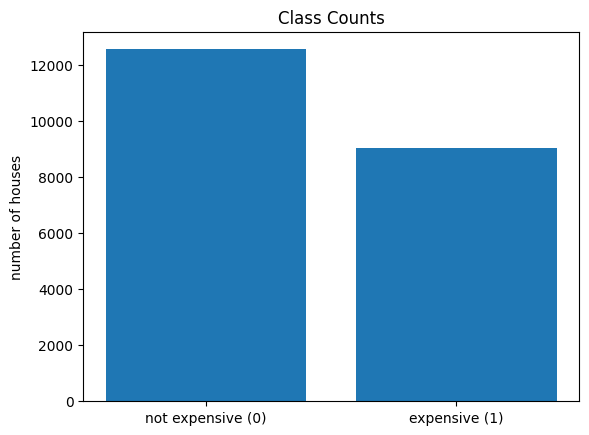

In [36]:
counts = y.value_counts()
print(counts)
print()
print("percent of each class")
print((counts / len(y) * 100).round(2))

plt.bar(["not expensive (0)", "expensive (1)"], [counts[0], counts[1]])
plt.title("Class Counts")
plt.ylabel("number of houses")
plt.show()

about 58% of the houses are class 0 and 42% are class 1. this is a small imbalance, not a big one, so I did not resample. I used a stratified split so both the train and test sets keep the same ratio, and I report precision, recall, F1, and ROC AUC instead of only accuracy

just guessing class 0 every time would get about 58% accuracy, so the model has to beat that

==================================================

### **Split the data 80% train and 20% test**

In [37]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print("train:", x_train.shape, " test:", x_test.shape)
print("percent expensive in train:", round(y_train.mean() * 100, 2))
print("percent expensive in test:", round(y_test.mean() * 100, 2))

train: (17288, 12)  test: (4323, 12)
percent expensive in train: 41.88
percent expensive in test: 41.89


==================================================

### **Train the model**

$h_\theta(x) = \sigma(b + w^\top x) = \frac{1}{1 + e^{-(b + w^\top x)}}$

$J = -\frac{1}{N}\sum_i \left[ y^{(i)} \log(h_\theta(x^{(i)})) + (1 - y^{(i)}) \log(1 - h_\theta(x^{(i)})) \right]$

trained with stochastic gradient descent in PyTorch: batch size = 64, learning rate = 0.1, epochs = 50. the data is shuffled every epoch and the features are scaled using the mean and std of the training data

final training loss = 0.3419


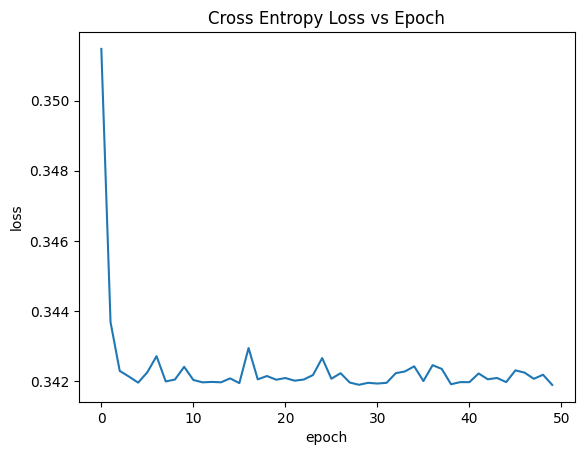

In [38]:
model = LogisticRegression(learning_rate=0.1, epochs=50, batch_size=64)
model.fit(x_train, y_train)

print("final training loss =", round(model.final_loss, 4))
model.loss_plot()

weights (on the scaled features)

In [39]:
model.print_weights(features)

bias = -0.4124
bedrooms = -0.1447
bathrooms = 0.2618
sqft_living = 1.2008
sqft_lot = 0.1754
floors = 0.2572
waterfront = 0.208
view = 0.3522
condition = 0.2393
grade = 1.7573
yr_built = -1.0223
lat = 1.2448
long = 0.122


since the features are scaled, the size of each weight shows how important it is. grade, lat, and sqft_living have the biggest positive weights, so better built, more northern (closer to Seattle), and bigger houses are more likely to be expensive. yr_built is negative, which means newer houses are less likely to be over \$500,000 once size and grade are the same

==================================================

### **Test the model**

confusion matrix
               pred 0   pred 1
actual 0       2220      292
actual 1        413     1398

accuracy    = 0.8369
precision   = 0.8272
recall      = 0.7719
specificity = 0.8838
f1 score    = 0.7986
roc auc     = 0.9232


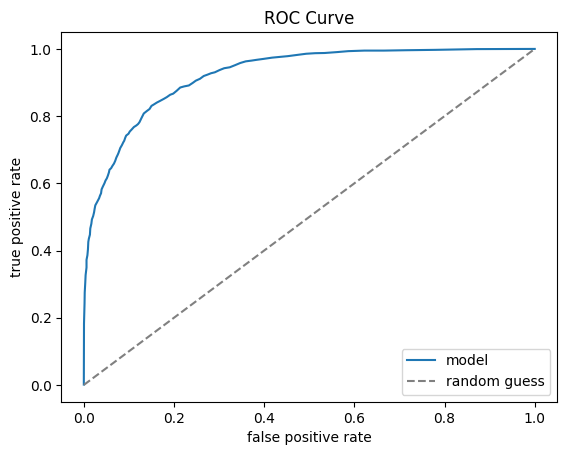

In [40]:
results = model.evaluate(x_test, y_test)
model.roc_plot(x_test, y_test)

**accuracy:** about 84% of the test houses are classified correctly, which is well above the 58% you get by always guessing class 0

**precision:** when the model says a house is expensive, it is right about 83% of the time

**recall:** the model finds about 77% of the houses that actually sold for more than \$500,000

**ROC AUC:** about 0.92, so the model ranks an expensive house above a cheaper one about 92% of the time

recall is a little lower than precision, so the model misses more expensive houses than it wrongly flags cheap ones. that fits with class 1 being the smaller class, but the gap is small, so the imbalance is not a big problem here

check against scikit-learn's logistic regression

In [42]:
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

#same scaling as my model
mean = x_train.mean()
std = x_train.std()

sk = SklearnLogisticRegression(max_iter=2000)
sk.fit((x_train - mean) / std, y_train)
sk_prob = sk.predict_proba((x_test - mean) / std)[:, 1]

print("sklearn accuracy =", round(accuracy_score(y_test, sk_prob >= 0.5), 4))
print("sklearn roc auc  =", round(roc_auc_score(y_test, sk_prob), 4))

sklearn accuracy = 0.8374
sklearn roc auc  = 0.9231


scikit-learn gets almost the same accuracy and AUC, so my SGD version is reaching the same answer